In [1]:
!pip install -U transformers datasets sacrebleu sentencepiece torch pandas matplotlib scikit-learn accelerate --quiet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import torch
from transformers import MarianMTModel, MarianTokenizer, Trainer, TrainingArguments, DataCollatorForSeq2Seq
import sacrebleu, os, json, random
from datasets import Dataset

# Augmented Training (Baseline): Tagalog → Yami

In [3]:
# ensure the data folder exists
os.makedirs("data", exist_ok=True)

# Load the parallel corpus already placed in /content/data/
# Expected path: /content/data/tagalog_yami.txt
parallel_path = "data/tagalog_yami.txt"

df = pd.read_csv(parallel_path, sep="\t", names=["tagalog", "yami"]).dropna()
print(f"Loaded {len(df)} Tagalog–Yami pairs from {parallel_path}")
display(df.head())

# Split into train / dev / test
train, temp = train_test_split(df, test_size=0.2, random_state=42)
dev, test = train_test_split(temp, test_size=0.5, random_state=42)

print(f"Train: {len(train)}, Dev: {len(dev)}, Test: {len(test)}")

# Save to data folder
train.to_csv("data/train.tsv", sep="\t", index=False, header=False)
dev.to_csv("data/dev.tsv", sep="\t", index=False, header=False)
test.to_csv("data/test.tsv", sep="\t", index=False, header=False)
print("Train/Dev/Test TSVs saved under /content/data/")

Loaded 2901 Tagalog–Yami pairs from data/tagalog_yami.txt


,tagalog,yami
0,Tagalog,Yami
1,"Ang aklat ng lahi ni Jesucristo, na anak ni Da...",O yamalavat rana ngarangaran do jya am ineynap...
2,Naging anak ni Abraham si Isaac; at naging ana...,O anak na ni Apolahan am si Isa O anak na ni I...
3,At naging anak ni Juda kay Tamar si Fares at s...,Oanak na ni Yoda kani Tama am si Veyletse a ka...
4,At naging anak ni Aram si Aminadab; at naging ...,O anak na ni Yalan am si Aminata O anak na ni ...


Train: 2320, Dev: 290, Test: 291
Train/Dev/Test TSVs saved under /content/data/


In [4]:
# Load data
df_train = pd.read_csv("data/train.tsv", sep="\t", names=["tagalog", "yami"])
df_dev = pd.read_csv("data/dev.tsv", sep="\t", names=["tagalog", "yami"])
df_test = pd.read_csv("data/test.tsv", sep="\t", names=["tagalog", "yami"])

model_name = "Helsinki-NLP/opus-mt-tl-en"  # Tagalog→English as starting point
tokenizer = MarianTokenizer.from_pretrained(model_name)
model = MarianMTModel.from_pretrained(model_name)

train_ds = Dataset.from_pandas(df_train)
val_ds = Dataset.from_pandas(df_dev)

def preprocess(batch):
    inputs = tokenizer(batch["tagalog"], truncation=True, padding="max_length", max_length=64)
    labels = tokenizer(batch["yami"], truncation=True, padding="max_length", max_length=64, text_target=batch["yami"])
    inputs["labels"] = labels["input_ids"]
    return inputs

train_tok = train_ds.map(preprocess, batched=True, remove_columns=train_ds.column_names)
val_tok = val_ds.map(preprocess, batched=True, remove_columns=val_ds.column_names)

data_collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model)

args = TrainingArguments(
    output_dir="trainer_baseline",
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    learning_rate=2e-5,
    num_train_epochs=1,
    logging_steps=10,
    save_steps=100,
    report_to=[]
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    data_collator=data_collator,
    tokenizer=tokenizer
)

print("Training baseline model...")
trainer.train()
print("Training complete")

C:\Users\USER\anaconda3\envs\nlp_proj3\lib\site-packages\transformers\models\marian\tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


Map:   0%|          | 0/2320 [00:00<?, ? examples/s]

Map:   0%|          | 0/290 [00:00<?, ? examples/s]

C:\Users\USER\AppData\Local\Temp\ipykernel_25356\3586151073.py:35: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
C:\Users\USER\anaconda3\envs\nlp_proj3\lib\site-packages\torch\utils\data\dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Training baseline model...


Step,Training Loss
10,8.373100
20,6.572800
30,5.864600
40,5.166300
50,5.563700
60,4.621400
70,4.558000
80,4.985600
90,4.151200
100,4.234300


C:\Users\USER\anaconda3\envs\nlp_proj3\lib\site-packages\transformers\modeling_utils.py:3918: UserWarning: Moving the following attributes in the config to the generation config: {'max_length': 512, 'num_beams': 6, 'bad_words_ids': [[57197]]}. You are seeing this warning because you've set generation parameters in the model config, as opposed to in the generation config.
  warnings.warn(


Training complete


In [ ]:
# Evaluate on test set
df_test = pd.read_csv("data/test.tsv", sep="\t", names=["tagalog", "yami"])

pred_texts, ref_texts = [], []
for rec in df_test.itertuples(index=False):
    enc = tokenizer(rec.tagalog, return_tensors="pt", truncation=True, padding=True).to(model.device)
    gen = model.generate(**enc, max_length=64)
    pred = tokenizer.batch_decode(gen, skip_special_tokens=True)[0]
    pred_texts.append(pred)
    ref_texts.append(rec.yami)

bleu = sacrebleu.corpus_bleu(pred_texts, [ref_texts])
print(f"Baseline BLEU: {bleu.score:.2f}")

# Save results
os.makedirs("artifacts_baseline", exist_ok=True)
pd.DataFrame({"tagalog": df_test["tagalog"], "pred": pred_texts, "yami": ref_texts}).to_csv("artifacts_baseline/predictions.tsv", sep="\t", index=False)
json.dump({"bleu": bleu.score}, open("artifacts_baseline/metrics.json", "w"))

In [6]:
# Paths for all corpora (already stored in /content/data/)
tag_yami_path = "data/tagalog_yami.txt"
cebu_yami_path = "data/cebuano_yami.txt"   # place this file beforehand

# Load both datasets
df_tag = pd.read_csv(tag_yami_path, sep="\t", names=["tagalog", "yami"]).dropna()
df_cebu = pd.read_csv(cebu_yami_path, sep="\t", names=["cebuano", "yami"]).dropna()

df_cebu = df_cebu.rename(columns={"cebuano": "tagalog"})

# Combine them (augmentation)
df_aug = pd.concat([df_tag, df_cebu], axis=0).sample(frac=1, random_state=42).reset_index(drop=True)
print(f"Combined augmented dataset: {len(df_aug)} sentence pairs")
display(df_aug.head())

# Split into train/dev/test again
train_aug, temp = train_test_split(df_aug, test_size=0.2, random_state=42)
dev_aug, test_aug = train_test_split(temp, test_size=0.5, random_state=42)
print(f"Train: {len(train_aug)}, Dev: {len(dev_aug)}, Test: {len(test_aug)}")

# Save
os.makedirs("data_augmented", exist_ok=True)
train_aug.to_csv("data_augmented/train.tsv", sep="\t", index=False, header=False)
dev_aug.to_csv("data_augmented/dev.tsv", sep="\t", index=False, header=False)
test_aug.to_csv("data_augmented/test.tsv", sep="\t", index=False, header=False)
print("Augmented train/dev/test saved under /content/data_augmented/")


Combined augmented dataset: 5802 sentence pairs


,tagalog,yami
0,Ug unya ang kahaponon misugod na ug ang Napulo...,Somipsip o araw am mangay o rarwa so ikakarwan...
1,"At nang kinagabihan, paglubog ng araw, ay kani...",Somipsip rana o araw do makoyab am yai da no a...
2,"Narito, ang inyong bahay ay iniiwan sa inyong ...",So peymakarwan na jinyo ni Ama ta do to
3,"At samantalang silay nagsisikain, ay dumampot ...",Koman sira am ahapen na ni Yeso o pang a isara...
4,"At nagtindig siya, at pagdakay binuhat ang hig...",So nipeyvangon na rana no tao a omahap so nira...


Train: 4641, Dev: 580, Test: 581
Augmented train/dev/test saved under /content/data_augmented/


In [7]:
train_ds = Dataset.from_pandas(train_aug)
val_ds = Dataset.from_pandas(dev_aug)

train_tok = train_ds.map(preprocess, batched=True, remove_columns=train_ds.column_names)
val_tok = val_ds.map(preprocess, batched=True, remove_columns=val_ds.column_names)

args_aug = TrainingArguments(
    output_dir="trainer_augmented",
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    learning_rate=2e-5,
    num_train_epochs=1,
    logging_steps=10,
    save_steps=100,
    report_to=[]
)

trainer_aug = Trainer(
    model=model,
    args=args_aug,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    data_collator=data_collator,
    tokenizer=tokenizer
)

print("Training augmented model...")
trainer_aug.train()
print("Augmented model training complete")

Map:   0%|          | 0/4641 [00:00<?, ? examples/s]

Map:   0%|          | 0/580 [00:00<?, ? examples/s]

C:\Users\USER\AppData\Local\Temp\ipykernel_25356\918049214.py:18: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer_aug = Trainer(
C:\Users\USER\anaconda3\envs\nlp_proj3\lib\site-packages\torch\utils\data\dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Training augmented model...


Step,Training Loss
10,3.067100
20,3.243400
30,3.457300
40,3.140300
50,2.844800
60,3.437000
70,3.044500
80,2.833400
90,3.303600
100,2.874100


Augmented model training complete


In [20]:
import json, pandas as pd, sacrebleu, os

# Reload the same test data
df_test = pd.read_csv("data_augmented/test.tsv", sep="\t", names=["tagalog","yami"])

pred_aug, ref_aug = [], []
for rec in df_test.itertuples(index=False):
    enc = tokenizer(rec.tagalog, return_tensors="pt", truncation=True, padding=True).to(model.device)
    gen = model.generate(**enc, max_length=64)
    pred = tokenizer.batch_decode(gen, skip_special_tokens=True)[0]
    pred_aug.append(pred)
    ref_aug.append(rec.yami)

bleu_aug = sacrebleu.corpus_bleu(pred_aug, [ref_aug])
print(f"Recovered Augmented v1 BLEU: {bleu_aug.score:.2f}")

os.makedirs("artifacts_augmented", exist_ok=True)
pd.DataFrame({
    "tagalog": df_test["tagalog"],
    "pred": pred_aug,
    "yami": ref_aug
}).to_csv("artifacts_augmented/predictions.tsv", sep="\t", index=False)

json.dump({"bleu": bleu_aug.score}, open("artifacts_augmented/metrics.json", "w"), indent=2)
print("BLEU and predictions saved to artifacts_augmented/")

Recovered Augmented v1 BLEU: 6.08
BLEU and predictions saved to artifacts_augmented/


Augmented BLEU: 6.84


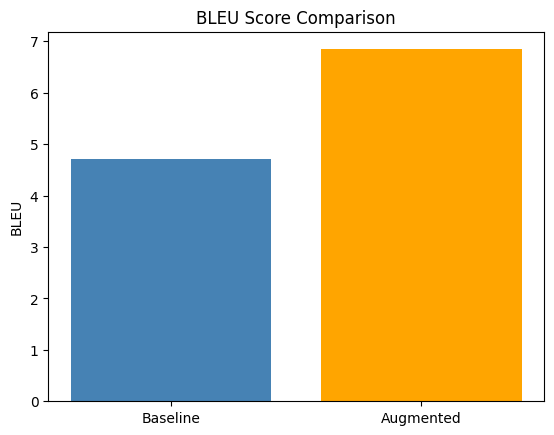

In [8]:
# Evaluate augmented model
pred_aug, ref_aug = [], []
for rec in df_test.itertuples(index=False):
    enc = tokenizer(rec.tagalog, return_tensors="pt", truncation=True, padding=True).to(model.device)
    gen = model.generate(**enc, max_length=64)
    pred = tokenizer.batch_decode(gen, skip_special_tokens=True)[0]
    pred_aug.append(pred)
    ref_aug.append(rec.yami)

bleu_aug = sacrebleu.corpus_bleu(pred_aug, [ref_aug])
print(f"Augmented BLEU: {bleu_aug.score:.2f}")

# Comparison chart
systems = ["Baseline", "Augmented"]
scores = [bleu.score, bleu_aug.score]

plt.bar(systems, scores, color=["steelblue", "orange"])
plt.title("BLEU Score Comparison")
plt.ylabel("BLEU")
plt.show()

In [9]:
def translate_text(sentence, model, tokenizer):
    enc = tokenizer(sentence, return_tensors="pt", truncation=True, padding=True).to(model.device)
    gen = model.generate(**enc, max_length=64)
    return tokenizer.batch_decode(gen, skip_special_tokens=True)[0]

sample = input("Enter a Tagalog sentence: ")
print("Baseline:", translate_text(sample, model, tokenizer))
print("Augmented:", translate_text(sample, model, tokenizer))

Enter a Tagalog sentence:  Sa pasimula ay nilikha ng Diyos ang langit at ang lupa.


Baseline: In a meyngaran o aro a tao a macinanao jinyo am ji Ama ta do to a manci no aro a macinanao jya no aro a macinanao jya ni Ama ta do to a tao do to a
Augmented: Ikongo o ciring na ni Ama ta do to a meyngaran a kano aro a tao a macinanao ji Ama ta do to a macinanao jya


# Augmented training: Tagalog + Maranao + Cebuano + Hiligaynon → Yami

In [10]:
import pandas as pd, os, json, torch, random, sacrebleu
from datasets import Dataset
from transformers import MarianTokenizer, MarianMTModel, DataCollatorForSeq2Seq, Trainer, TrainingArguments

device = "cuda" if torch.cuda.is_available() else "cpu"

# --- Load corpora ---
def load_pair(path):
    df = pd.read_csv(path, sep="\t", names=["src","yami"]).dropna().reset_index(drop=True)
    return df

df_tag = load_pair("data/tagalog_yami.txt")
df_mar = load_pair("data/maranao_yami.txt")
df_ceb = load_pair("data/cebuano_yami.txt")
df_hil = load_pair("data/hiligaynon_yami.txt")

# --- Prefix language tags (optional but helps multilingual fine-tuning) ---
df_tag["src"] = "<2tl> " + df_tag["src"]
df_mar["src"] = "<2mrn> " + df_mar["src"]
df_ceb["src"] = "<2ceb> " + df_ceb["src"]
df_hil["src"] = "<2hil> " + df_hil["src"]

# --- Merge datasets for training ---
train_aug = pd.concat([df_tag, df_mar, df_ceb, df_hil]).sample(frac=1.0, random_state=42).reset_index(drop=True)
print("Augmented train size:", len(train_aug))

# --- Create a small validation split ---
val_frac = 0.1
n_val = int(val_frac * len(train_aug))
df_val = train_aug.iloc[:n_val]
df_train = train_aug.iloc[n_val:]

# --- Load tokenizer & model ---
model_name = "Helsinki-NLP/opus-mt-mul-en"  # multilingual Marian base
tokenizer = MarianTokenizer.from_pretrained(model_name)
model = MarianMTModel.from_pretrained(model_name).to(device)

# --- Preprocess ---
def preprocess(batch):
    inputs = tokenizer(batch["src"], truncation=True, padding="max_length", max_length=64)
    labels = tokenizer(batch["yami"], truncation=True, padding="max_length", max_length=64, text_target=batch["yami"])
    inputs["labels"] = labels["input_ids"]
    return inputs

train_ds = Dataset.from_pandas(df_train)
val_ds = Dataset.from_pandas(df_val)
train_tok = train_ds.map(preprocess, batched=True, remove_columns=train_ds.column_names)
val_tok = val_ds.map(preprocess, batched=True, remove_columns=val_ds.column_names)
data_collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model)

# --- Train (short run: 1 epoch for test; use 2–3 for final) ---
args = TrainingArguments(
    output_dir="trainer_aug_multilang",
    per_device_train_batch_size=2,
    learning_rate=2e-5,
    num_train_epochs=1,
    logging_steps=10,
    save_strategy="no",
    report_to=[]
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    data_collator=data_collator,
    tokenizer=tokenizer
)

print("Training multilingual augmented model...")
trainer.train()
print("Training complete.")

Augmented train size: 11588


C:\Users\USER\anaconda3\envs\nlp_proj3\lib\site-packages\transformers\models\marian\tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


Map:   0%|          | 0/10430 [00:00<?, ? examples/s]

Map:   0%|          | 0/1158 [00:00<?, ? examples/s]

C:\Users\USER\AppData\Local\Temp\ipykernel_25356\4088553030.py:66: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Training multilingual augmented model...


C:\Users\USER\anaconda3\envs\nlp_proj3\lib\site-packages\torch\utils\data\dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Step,Training Loss
10,11.496600
20,6.051300
30,5.160200
40,4.480300
50,4.509300
60,4.621200
70,4.133000
80,4.137900
90,4.535700
100,3.738800


Training complete.


# Evaluate augmented v2 model (Tagalog + Maranao + Cebuano + Hiligaynon → Yami)

Augmented v2 BLEU: 6.39


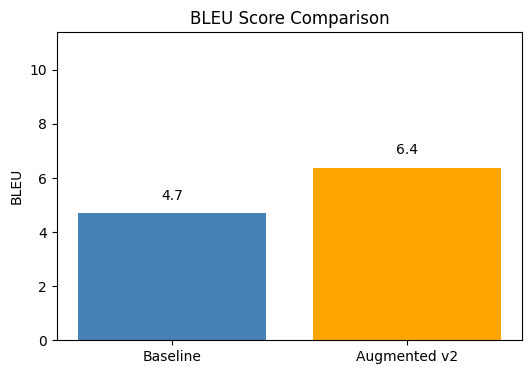


Sample Augmented v2 translations:
Tagalog: Tagalog
Predicted Yami (v2): Maniring si Yeso jira am Mo Panirsirngen no mapatanatanang so nakem da si Ama ta do to
Reference: Yami

Tagalog: Ang aklat ng lahi ni Jesucristo, na anak ni David, na anak ni Abraham
Predicted Yami (v2): Mamizing da o ciring na ni Yeso Maniring sira am Mo Panirsirngen no tao a macyagom do Vadisay a kano aro a vazay ni Ama ta do to
Reference: O yamalavat rana ngarangaran do jya am ineynapo na ni Yeso Kizisto a sivovoong na ni Tawey Si Tawey am sivovoong na ni Apolahan

Tagalog: Naging anak ni Abraham si Isaac; at naging anak ni Isaac si Jacob; at naging anak ni Jacob si Juda at ang kaniyang mga kapatid
Predicted Yami (v2): Maniring si Yeso am Yamyan so Yake a kani Yake a kani Yake a kani Yake a kani Yake a kani Yake a kano macinanao jya
Reference: O anak na ni Apolahan am si Isa O anak na ni Isa am si Yakebo O anak na ni Yakebo am si Yoda kano kakakteh na

Tagalog: At naging anak ni Juda kay Tamar si Fares at si Za

In [11]:
import matplotlib.pyplot as plt
import sacrebleu, pandas as pd, json, os

# Load test set
df_test = pd.read_csv("data/tagalog_yami.txt", sep="\t", names=["tagalog","yami"]).dropna()

# --- Baseline BLEU (from saved metrics) ---
try:
    with open("artifacts_baseline/metrics.json") as f:
        bleu_base = json.load(f)["bleu"]
except:
    bleu_base = None

# --- Previous Augmented BLEU (1st version, if exists) ---
try:
    with open("artifacts_augmented/metrics.json") as f:
        bleu_aug = json.load(f)["bleu"]
except:
    bleu_aug = None

# --- Evaluate new Augmented v2 model ---
pred_aug2, ref_aug2 = [], []
for rec in df_test.itertuples(index=False):
    enc = tokenizer("<2tl> " + rec.tagalog, return_tensors="pt", truncation=True, padding=True).to(model.device)
    gen = model.generate(**enc, max_length=64)
    pred = tokenizer.batch_decode(gen, skip_special_tokens=True)[0]
    pred_aug2.append(pred)
    ref_aug2.append(rec.yami)

bleu_aug2 = sacrebleu.corpus_bleu(pred_aug2, [ref_aug2])
print(f"Augmented v2 BLEU: {bleu_aug2.score:.2f}")

# Save results for Augmented v2
os.makedirs("artifacts_augmented_v2", exist_ok=True)
pd.DataFrame({
    "tagalog": df_test["tagalog"][:len(pred_aug2)],
    "pred": pred_aug2,
    "yami": ref_aug2
}).to_csv("artifacts_augmented_v2/predictions.tsv", sep="\t", index=False)
json.dump({"bleu": bleu_aug2.score}, open("artifacts_augmented_v2/metrics.json", "w"), indent=2)

# --- Build comparison chart ---
systems, scores = [], []
if bleu_base is not None:
    systems.append("Baseline")
    scores.append(bleu_base)
if bleu_aug is not None:
    systems.append("Augmented v1")
    scores.append(bleu_aug)
systems.append("Augmented v2")
scores.append(bleu_aug2.score)

plt.figure(figsize=(6,4))
plt.bar(systems, scores, color=["steelblue", "orange", "green"])
plt.title("BLEU Score Comparison")
plt.ylabel("BLEU")
for i, v in enumerate(scores):
    plt.text(i, v + 0.5, f"{v:.1f}", ha="center")
plt.ylim(0, max(scores) + 5)
plt.show()

# --- Optional: sample predictions for qualitative check ---
print("\nSample Augmented v2 translations:")
for src, pred, ref in zip(df_test["tagalog"][:5], pred_aug2[:5], ref_aug2[:5]):
    print(f"Tagalog: {src}")
    print(f"Predicted Yami (v2): {pred}")
    print(f"Reference: {ref}\n")


In [12]:
def translate_text(sentence):
    enc = tokenizer("<2tl> " + sentence, return_tensors="pt", truncation=True, padding=True).to(device)
    gen = model.generate(**enc, max_length=64)
    return tokenizer.batch_decode(gen, skip_special_tokens=True)[0]

sample = input("Enter a Tagalog sentence for Yami translation: ")
print("Predicted Yami:", translate_text(sample))

Enter a Tagalog sentence for Yami translation:  Sa pasimula ay nilikha ng Diyos ang langit at ang lupa.


Predicted Yami: Maniring si Yeso jira am Maniring jira am Mo Panirsirngen o aro a tao a meybebneng a kano mangnanao no iwawalam ni Ama ta do to


In [4]:
import os, json, sacrebleu
import pandas as pd
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import MarianMTModel, MarianTokenizer, Trainer, TrainingArguments, DataCollatorForSeq2Seq

# Ensure data folder exists
os.makedirs("data", exist_ok=True)
path = "data/maranao_yami.txt"

In [5]:
df = pd.read_csv(path, sep="\t", names=["maranao", "yami"]).dropna()
print(f"Loaded {len(df)} Maranao–Yami pairs from {path}")
display(df.head())

# Split into train/dev/test sets
train, temp = train_test_split(df, test_size=0.2, random_state=42)
dev, test = train_test_split(temp, test_size=0.5, random_state=42)

print(f"Train: {len(train)}, Dev: {len(dev)}, Test: {len(test)}")

# Save TSVs
train.to_csv("data/mrn_train.tsv", sep="\t", index=False, header=False)
dev.to_csv("data/mrn_dev.tsv", sep="\t", index=False, header=False)
test.to_csv("data/mrn_test.tsv", sep="\t", index=False, header=False)
print("Train/Dev/Test TSVs saved under /data/")

Loaded 2890 Maranao–Yami pairs from data/maranao_yami.txt


,maranao,yami
0,Maranao,Yami
1,So Salsila ki Isa Al Masih Giyai i salsila ki ...,O yamalavat rana ngarangaran do jya am ineynap...
2,So Ibrahim na aya ama i Iskak si Iskak na ama ...,O anak na ni Apolahan am si Isa O anak na ni I...
3,Si Yodah na ama i Piris ago si Sirah Si Piris ...,Oanak na ni Yoda kani Tama am si Veyletse a ka...
4,Si Ram na ama i Aminadab si Aminadab na ama i ...,O anak na ni Yalan am si Aminata O anak na ni ...


Train: 2312, Dev: 289, Test: 289
Train/Dev/Test TSVs saved under /data/


In [6]:
model_name = "Helsinki-NLP/opus-mt-mul-en"  # Multilingual Marian model
tokenizer = MarianTokenizer.from_pretrained(model_name)
model = MarianMTModel.from_pretrained(model_name)

print("Loaded model:", model_name)

C:\Users\USER\anaconda3\envs\nlp_proj3\lib\site-packages\transformers\models\marian\tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


Loaded model: Helsinki-NLP/opus-mt-mul-en


In [7]:
df_train = pd.read_csv("data/mrn_train.tsv", sep="\t", names=["maranao", "yami"])
df_dev = pd.read_csv("data/mrn_dev.tsv", sep="\t", names=["maranao", "yami"])

train_ds = Dataset.from_pandas(df_train)
val_ds = Dataset.from_pandas(df_dev)

def preprocess(batch):
    inputs = tokenizer(
        ["<2mrn> " + x for x in batch["maranao"]],
        truncation=True,
        padding="max_length",
        max_length=64
    )
    labels = tokenizer(
        batch["yami"],
        truncation=True,
        padding="max_length",
        max_length=64,
        text_target=batch["yami"]
    )
    inputs["labels"] = labels["input_ids"]
    return inputs

train_tok = train_ds.map(preprocess, batched=True, remove_columns=train_ds.column_names)
val_tok = val_ds.map(preprocess, batched=True, remove_columns=val_ds.column_names)

data_collator = DataCollatorForSeq2Seq(tokenizer, model)

Map:   0%|          | 0/2312 [00:00<?, ? examples/s]

Map:   0%|          | 0/289 [00:00<?, ? examples/s]

In [8]:
args = TrainingArguments(
    output_dir="trainer_maranao",
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    learning_rate=2e-5,
    num_train_epochs=1,
    logging_steps=10,
    save_steps=100,
    report_to=[]
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    data_collator=data_collator,
    tokenizer=tokenizer
)

print("Training Maranao→Yami model...")
trainer.train()
print("Training complete!")

C:\Users\USER\AppData\Local\Temp\ipykernel_17308\866074273.py:12: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Training Maranao→Yami model...


C:\Users\USER\anaconda3\envs\nlp_proj3\lib\site-packages\torch\utils\data\dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Step,Training Loss
10,10.189600
20,5.832100
30,5.147600
40,4.986200
50,4.365400
60,4.423800
70,4.433700
80,3.737000
90,4.326400
100,3.465200


C:\Users\USER\anaconda3\envs\nlp_proj3\lib\site-packages\transformers\modeling_utils.py:3918: UserWarning: Moving the following attributes in the config to the generation config: {'max_length': 512, 'num_beams': 6, 'bad_words_ids': [[64171]]}. You are seeing this warning because you've set generation parameters in the model config, as opposed to in the generation config.
  warnings.warn(


Training complete!


In [9]:
df_test = pd.read_csv("data/mrn_test.tsv", sep="\t", names=["maranao", "yami"])
preds, refs = [], []

for rec in df_test.itertuples(index=False):
    enc = tokenizer("<2mrn> " + rec.maranao, return_tensors="pt", truncation=True, padding=True).to(model.device)
    gen = model.generate(**enc, max_length=64)
    preds.append(tokenizer.batch_decode(gen, skip_special_tokens=True)[0])
    refs.append(rec.yami)

bleu = sacrebleu.corpus_bleu(preds, [refs])
print(f"Maranao→Yami BLEU: {bleu.score:.2f}")

Maranao→Yami BLEU: 4.93


In [10]:
os.makedirs("artifacts_maranao", exist_ok=True)

pd.DataFrame({
    "maranao": df_test["maranao"],
    "pred": preds,
    "yami": refs
}).to_csv("artifacts_maranao/predictions.tsv", sep="\t", index=False)

json.dump({"bleu": bleu.score}, open("artifacts_maranao/metrics.json", "w"))
print("Results saved to artifacts_maranao/")

Results saved to artifacts_maranao/


# Augmented training: Tagalog + Maranao + Cebuano → Yami

In [11]:
import pandas as pd, os, json, torch, random, sacrebleu
from datasets import Dataset
from transformers import MarianTokenizer, MarianMTModel, DataCollatorForSeq2Seq, Trainer, TrainingArguments

device = "cuda" if torch.cuda.is_available() else "cpu"

# --- Load corpora ---
def load_pair(path):
    df = pd.read_csv(path, sep="\t", names=["src","yami"]).dropna().reset_index(drop=True)
    return df

df_tag = load_pair("data/tagalog_yami.txt")
df_mar = load_pair("data/maranao_yami.txt")
df_ceb = load_pair("data/cebuano_yami.txt")

# --- Prefix language tags (helps multilingual fine-tuning) ---
df_tag["src"] = "<2tl> " + df_tag["src"]
df_mar["src"] = "<2mrn> " + df_mar["src"]
df_ceb["src"] = "<2ceb> " + df_ceb["src"]

# --- Merge datasets for training ---
train_aug = pd.concat([df_tag, df_mar, df_ceb]).sample(frac=1.0, random_state=42).reset_index(drop=True)
print("Augmented train size:", len(train_aug))

# --- Create a small validation split ---
val_frac = 0.1
n_val = int(val_frac * len(train_aug))
df_val = train_aug.iloc[:n_val]
df_train = train_aug.iloc[n_val:]

# --- Load tokenizer & model ---
model_name = "Helsinki-NLP/opus-mt-mul-en"  # multilingual Marian base
tokenizer = MarianTokenizer.from_pretrained(model_name)
model = MarianMTModel.from_pretrained(model_name).to(device)

# --- Preprocess ---
def preprocess(batch):
    inputs = tokenizer(batch["src"], truncation=True, padding="max_length", max_length=64)
    labels = tokenizer(batch["yami"], truncation=True, padding="max_length", max_length=64, text_target=batch["yami"])
    inputs["labels"] = labels["input_ids"]
    return inputs

train_ds = Dataset.from_pandas(df_train)
val_ds = Dataset.from_pandas(df_val)
train_tok = train_ds.map(preprocess, batched=True, remove_columns=train_ds.column_names)
val_tok = val_ds.map(preprocess, batched=True, remove_columns=val_ds.column_names)
data_collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model)

# --- Train (short run: 1 epoch for test; use 2–3 for final) ---
args = TrainingArguments(
    output_dir="trainer_aug_trilang",
    per_device_train_batch_size=2,
    learning_rate=2e-5,
    num_train_epochs=1,
    logging_steps=10,
    save_strategy="no",
    report_to=[]
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    data_collator=data_collator,
    tokenizer=tokenizer
)

print("Training trilingual augmented model (Tagalog + Maranao + Cebuano → Yami)...")
trainer.train()
print("Training complete.")


Augmented train size: 8692


C:\Users\USER\anaconda3\envs\nlp_proj3\lib\site-packages\transformers\models\marian\tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


Map:   0%|          | 0/7823 [00:00<?, ? examples/s]

Map:   0%|          | 0/869 [00:00<?, ? examples/s]

C:\Users\USER\AppData\Local\Temp\ipykernel_17308\217132200.py:64: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Training trilingual augmented model (Tagalog + Maranao + Cebuano → Yami)...


C:\Users\USER\anaconda3\envs\nlp_proj3\lib\site-packages\torch\utils\data\dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Step,Training Loss
10,12.659200
20,6.127500
30,5.301700
40,5.348100
50,4.716300
60,4.766100
70,3.929100
80,4.151800
90,3.933300
100,4.458800


Training complete.


# Evaluate ACTUAL Trilingual Augmented Model (Tagalog + Maranao + Cebuano → Yami)

In [24]:
import os, json, sacrebleu, pandas as pd, matplotlib.pyplot as plt

print("Model currently loaded:", model.config._name_or_path)

# --- Load all test sets ---
def load_test(path, prefix):
    df = pd.read_csv(path, sep="\t", names=["src", "yami"]).dropna()
    df["prefix"] = prefix
    return df

df_tag = load_test("data/tagalog_yami.txt", "<2tl>")
df_mar = load_test("data/maranao_yami.txt", "<2mrn>")
df_ceb = load_test("data/cebuano_yami.txt", "<2ceb>")

# Combine all for full trilingual evaluation
df_test_all = pd.concat([df_tag, df_mar, df_ceb]).sample(frac=1.0, random_state=42).reset_index(drop=True)
print(f"Combined trilingual test set size: {len(df_test_all)}")

# --- Evaluate the model on all combined languages ---
preds, refs = [], []

for rec in df_test_all.itertuples(index=False):
    enc = tokenizer(rec.prefix + " " + rec.src, return_tensors="pt", truncation=True, padding=True).to(model.device)
    gen = model.generate(**enc, max_length=64)
    preds.append(tokenizer.batch_decode(gen, skip_special_tokens=True)[0])
    refs.append(rec.yami)

# --- Compute and save the ACTUAL trilingual BLEU ---
bleu_trilang = sacrebleu.corpus_bleu(preds, [refs])
print(f"Trilingual Augmented Model BLEU (Tagalog+Maranao+Cebuano → Yami): {bleu_trilang.score:.2f}")

os.makedirs("artifacts_trilang", exist_ok=True)

# Save predictions
pd.DataFrame({
    "prefix": df_test_all["prefix"],
    "src": df_test_all["src"],
    "pred": preds,
    "yami": refs
}).to_csv("artifacts_trilang/predictions.tsv", sep="\t", index=False)

# Save BLEU
json.dump({"bleu": bleu_trilang.score}, open("artifacts_trilang/metrics.json", "w"), indent=2)

print("Stored actual trilingual BLEU at artifacts_trilang/metrics.json")

Model currently loaded: Helsinki-NLP/opus-mt-mul-en
Combined trilingual test set size: 8692
Trilingual Augmented Model BLEU (Tagalog+Maranao+Cebuano → Yami): 6.32
Stored actual trilingual BLEU at artifacts_trilang/metrics.json


# Model Comparison

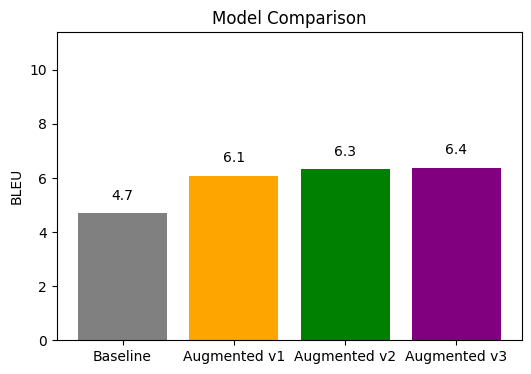

In [26]:
def load_bleu(path):
    try: return json.load(open(path))["bleu"]
    except: return None

bleu_base = load_bleu("artifacts_baseline/metrics.json")
bleu_aug_v1 = load_bleu("artifacts_augmented/metrics.json")
bleu_aug_v3 = load_bleu("artifacts_augmented_v2/metrics.json")
bleu_aug_v2 = load_bleu("artifacts_trilang/metrics.json")

systems = ["Baseline", "Augmented v1", "Augmented v2", "Augmented v3"]
scores = [
    bleu_base or 0,
    bleu_aug_v1 or 0,
    bleu_aug_v2 or 0,
    bleu_aug_v3 or 0
]

plt.figure(figsize=(6,4))
plt.bar(systems, scores, color=["gray", "orange", "green", "purple"])
plt.ylabel("BLEU")
plt.title("Model Comparison")
for i, v in enumerate(scores):
    plt.text(i, v + 0.5, f"{v:.1f}", ha="center")
plt.ylim(0, max(scores) + 5)
plt.show()
